# Capture settings test

**Question:** what is the lowest **resolution**, **frame rate** and **tracker** combination that still captures what the behaviors need, and what does it cost to process?

| Part | Asks | Data | When |
|---|---|---|---|
| **A. Resolution** | Does the camera see bodies, and postures? | WILDTRACK now, GoPro test footage later | Now |
| **B. Frame rate + tracker** | Do tracks and speeds hold up at lower frame rates? | 30 fps GoPro clip | After the GoPro test |
| **C. Processing cost** | How long does each setting take to process? | Any frames | Now |
| **D. Decision** | Cheapest setting that passes everything | Results of A–C | After the GoPro test |

**How it works:** record once at high quality, simulate every lower setting from that recording, and compare each one with the full-quality *reference* run.

**Every expensive step saves its results** to `Detection/Outputs/capture_test/`. Re-running a cell reuses the saved file instead of re-running YOLO. Pass `force=True` to recompute.

**Parts that need the GoPro clip skip themselves** until `GOPRO_CLIP` is set in the settings cell.

## 0. Setup

In [1]:
%matplotlib inline
import sys, json, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# find the repo root (the folder holding project_config.py), wherever this notebook sits inside the repo
def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "project_config.py").exists():
            return p
    raise FileNotFoundError("project_config.py not found above this notebook")

REPO = find_repo_root()
sys.path.insert(0, str(REPO))
from project_config import load_config

cfg = load_config()
print("Repo:", REPO)
print("Camera:", cfg["camera"], "| frames:", cfg["frames_dir"])

Repo: /Users/temp/Documents/GitHub/Negotiating-Space
Camera: C1 | frames: /Volumes/Backup Drive/GSAPP Flash/wildtrack/Wildtrack_dataset_full/Wildtrack_dataset/Image_subsets/C1


### Settings

Everything you might change lives here. Set `GOPRO_CLIP` (and later `GOPRO_H`) once the test footage exists.

In [2]:
# ---------- model ----------
MODEL = "yolov8m-pose.pt"
DEVICE = "mps"  # Apple GPU; falls back to CPU if unavailable
CONF = 0.20

# ---------- Part A: resolution ----------
SCALES = [1.0, 0.75, 0.5, 0.375, 0.25]  # 1.0 = native resolution (the reference)
N_SAMPLE_FRAMES = 40  # frames sampled evenly across the clip
KP_CONF_MIN = 0.5  # keypoint confidence needed to trust it
IOU_MATCH = 0.5  # boxes overlapping this much = same person
HEIGHT_BINS = np.arange(0, 420, 20)  # person-height bins (pixels) for the curves

# ---------- Part B: frame rate + tracker ----------
FPS_LIST = [30, 15, 10, 5, 4, 2, 1]
TRACKERS = ["bytetrack", "botsort_reid", "ground_distance"]
REFERENCE_TRACKER = (
    "bytetrack"  # reference = this tracker at the clip's full frame rate
)
CLIP_SECONDS = 120  # how much of the clip to use (processing grows fast)
IMGSZ_B = None  # None = native; set to the size chosen in Part A
BUFFER_S = 2.0  # how long a lost person is remembered, in seconds
SPEED_WINDOW_S = 3.0  # speed is measured over this window (smoothing)
STATIONARY_MS = 0.5  # below this = stationary (Salazar-Miranda et al.)
MAX_SPEED_MS = 3.0  # ground_distance tracker: fastest plausible movement
PIXEL_SPEED_PX_S = 400  # ground_distance tracker without a homography

# ---------- Part C: processing cost ----------
MODELS_TO_TIME = ["yolov8n-pose.pt", "yolov8m-pose.pt"]
TIMING_FRAMES = 100
DAYLIGHT_HOURS = 12
DAYS = [1, 2, 4]

# ---------- data ----------
WILDTRACK_FRAMES = Path(cfg["frames_dir"])  # .../Image_subsets/C1
WILDTRACK_ROOT = WILDTRACK_FRAMES.parents[1]  # .../Wildtrack_dataset
WILDTRACK_VIEW = int(str(cfg["camera"]).lstrip("Cc")) - 1  # C1 -> view 0

GOPRO_CLIP = None  # e.g. Path("/Volumes/<drive>/<site>/test_clip.MP4")
GOPRO_CLIP_FPS = 30
GOPRO_H = (
    None  # e.g. REPO / "Data/Sites/<site>/<cam>/H_<cam>_master.npy" (pixels -> meters)
)

# ---------- outputs ----------
OUT = REPO / "Test" / "capture_settings_test" / "Outputs"  # this notebook's own outputs
OUT.mkdir(parents=True, exist_ok=True)
print("Saving results to:", OUT)

Saving results to: /Users/temp/Documents/GitHub/Negotiating-Space/Test/capture_settings_test/Outputs


### Pass criteria

**Decided before looking at any results**, so the results can't nudge them. Change them here, not after the fact.

In [3]:
CRITERIA = {
    "detect_recall_min": 0.95,  # keeps at least 95% of the people the reference run finds
    "pose_keep_min": 0.90,  # of people whose hips/knees are usable at full res, 90% stay usable
    "speed_err_max": 0.10,  # median speed error vs reference, m/s
    "track_pieces_max": 1.5,  # a reference track splits into at most 1.5 pieces on average
}
CRITERIA

{'detect_recall_min': 0.95,
 'pose_keep_min': 0.9,
 'speed_err_max': 0.1,
 'track_pieces_max': 1.5}

### Helpers

Shared tools: device, frame loading, detection, box matching. Nothing to change here.

In [4]:
def pick_device(preferred=DEVICE):
    if preferred == "mps":
        import torch

        return "mps" if torch.backends.mps.is_available() else "cpu"
    return preferred


DEV = pick_device()
print("Device:", DEV)

HIP, KNEE = [11, 12], [13, 14]  # COCO keypoint indices


def imgsz_for(shape, scale=1.0):
    # processing size = longest image side, rounded up to a multiple of 32 (what YOLO expects)
    h, w = shape[:2]
    return max(320, int(math.ceil(max(h, w) * scale / 32) * 32))


def even_sample(items, n):
    idx = np.linspace(0, len(items) - 1, min(n, len(items))).round().astype(int)
    return [items[i] for i in sorted(set(idx))]


def frames_from_folder(folder, n):
    files = sorted(Path(folder).glob("*.png")) or sorted(Path(folder).glob("*.jpg"))
    for f in even_sample(files, n):
        yield f.stem, cv2.imread(str(f))


def frames_from_video(path, n):
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for i in even_sample(list(range(total)), n):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ok, img = cap.read()
        if ok:
            yield f"{i:07d}", img
    cap.release()


def detect(model, img, imgsz):
    # returns boxes (n,4), confidences (n,), keypoint confidences (n,17)
    r = model(img, imgsz=imgsz, conf=CONF, device=DEV, verbose=False)[0]
    if len(r.boxes) == 0:
        return np.zeros((0, 4)), np.zeros(0), np.zeros((0, 17))
    return (
        r.boxes.xyxy.cpu().numpy(),
        r.boxes.conf.cpu().numpy(),
        r.keypoints.conf.cpu().numpy(),
    )


def pose_ok(kp_conf):
    # usable for posture rules: at least one hip AND at least one knee confident
    return (kp_conf[:, HIP].max(axis=1) > KP_CONF_MIN) & (
        kp_conf[:, KNEE].max(axis=1) > KP_CONF_MIN
    )


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def match(a, b, thr=IOU_MATCH):
    # greedy one-to-one matching; for each box in a, the index of its match in b, or -1
    out = -np.ones(len(a), dtype=int)
    m = iou_matrix(a, b)
    while m.size and m.max() >= thr:
        i, j = np.unravel_index(m.argmax(), m.shape)
        out[i] = j
        m[i, :] = -1
        m[:, j] = -1
    return out

Device: mps


---
## A. Resolution: does the camera see bodies and postures?

For each sampled frame: detect at native resolution (the **reference**), then shrink the frame to each `SCALE` and detect again. Every reference person is then checked: **found at this scale? hips and knees still usable? how tall in pixels at this scale?**

Shrinking simulates both a lower capture resolution and people standing farther away. Both reduce **pixels per person**, which is what actually limits detection.

In [5]:
def run_scale_sweep(frame_iter, label, force=False):
    cache = OUT / f"A_{label}_detections.csv"
    if cache.exists() and not force:
        print(f"Using saved {cache.name}")
        return pd.read_csv(cache, dtype={"frame": str})
    model = YOLO(MODEL)
    rows = []
    for name, img in frame_iter:
        for s in SCALES:
            small = (
                img
                if s == 1.0
                else cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
            )
            boxes, conf, kpc = detect(model, small, imgsz_for(small.shape))
            ok = pose_ok(kpc) if len(boxes) else np.zeros(0, bool)
            for k in range(len(boxes)):
                x1, y1, x2, y2 = boxes[k] / s  # back to native coordinates
                rows.append(
                    dict(
                        frame=name,
                        scale=s,
                        x1=x1,
                        y1=y1,
                        x2=x2,
                        y2=y2,
                        conf=conf[k],
                        h_px=boxes[k, 3] - boxes[k, 1],  # height at this scale
                        pose_ok=bool(ok[k]),
                        hip_c=kpc[k, HIP].max(),
                        knee_c=kpc[k, KNEE].max(),
                    )
                )
        print(f"  {label}: frame {name} done", end="\r")
    df = pd.DataFrame(rows)
    df.to_csv(cache, index=False)
    print(f"\nSaved {cache.name}: {len(df)} detections")
    return df


def compare_to_reference(det, ref_boxes_by_frame=None):
    # One row per reference person per scale.
    # Reference = native-resolution detections, unless ground-truth boxes are passed in.
    rows = []
    for frame, g in det.groupby("frame"):
        if ref_boxes_by_frame is None:
            ref = g[g.scale == 1.0]
            ref_boxes, ref_pose = (
                ref[["x1", "y1", "x2", "y2"]].values,
                ref.pose_ok.values,
            )
        else:
            ref_boxes = ref_boxes_by_frame.get(frame, np.zeros((0, 4)))
            ref_pose = np.full(len(ref_boxes), np.nan)  # ground truth has no keypoints
        for s in SCALES:
            d = g[g.scale == s]
            m = match(ref_boxes, d[["x1", "y1", "x2", "y2"]].values)
            for i, j in enumerate(m):
                rows.append(
                    dict(
                        frame=frame,
                        scale=s,
                        h_px=(ref_boxes[i, 3] - ref_boxes[i, 1]) * s,
                        detected=j >= 0,
                        pose_ok=bool(d.pose_ok.values[j]) if j >= 0 else False,
                        ref_pose_ok=ref_pose[i],
                    )
                )
    return pd.DataFrame(rows)


def summarize_A(cmp, native_long_side):
    s = cmp.groupby("scale").agg(
        people=("detected", "size"), recall=("detected", "mean")
    )
    s = s.join(
        cmp[cmp.ref_pose_ok == True]
        .groupby("scale")["pose_ok"]
        .mean()
        .rename("pose_keep")
    )
    s["imgsz"] = [imgsz_for((native_long_side, native_long_side), sc) for sc in s.index]
    s["passes"] = (s.recall >= CRITERIA["detect_recall_min"]) & (
        s.pose_keep >= CRITERIA["pose_keep_min"]
    )
    return s.sort_index(ascending=False)


def curve(cmp, col, mask=None, min_n=10):
    c = cmp if mask is None else cmp[mask]
    g = c.groupby(pd.cut(c.h_px, HEIGHT_BINS), observed=True)[col].agg(["mean", "size"])
    g = g[g["size"] >= min_n]  # skip bins with too few people to trust
    return np.array([iv.mid for iv in g.index]), g["mean"].values


def height_threshold(x, y, target):
    # smallest person height (px) from which the rate stays at or above the target
    ok = y >= target
    for i in range(len(ok)):
        if ok[i:].all():
            return x[i]
    return np.nan


def plot_curves(cmp, title, gt=None):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    x, y = curve(cmp, "detected")
    ax.plot(x, y, "o-", label="detected (vs reference)")
    x, y = curve(cmp, "pose_ok", cmp.ref_pose_ok == True)
    ax.plot(x, y, "s-", label="hips + knees usable (of those usable at full res)")
    if gt is not None:
        x, y = curve(gt, "detected")
        ax.plot(x, y, "^--", alpha=0.7, label="detected (vs ground truth)")
    ax.axhline(CRITERIA["detect_recall_min"], ls=":", c="grey", lw=0.8)
    ax.axhline(CRITERIA["pose_keep_min"], ls=":", c="grey", lw=0.8)
    ax.set_xlabel("person height in pixels")
    ax.set_ylabel("share of people")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_title(title)
    fig.savefig(
        OUT / f"A_curves_{title.split()[0].lower().strip(':')}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

### A1–A5. WILDTRACK (run now)

In [6]:
detA_wt = run_scale_sweep(
    frames_from_folder(WILDTRACK_FRAMES, N_SAMPLE_FRAMES), "wildtrack"
)
cmpA_wt = compare_to_reference(detA_wt)

native_wt = cv2.imread(str(sorted(WILDTRACK_FRAMES.glob("*.png"))[0])).shape
summaryA_wt = summarize_A(cmpA_wt, max(native_wt[:2]))
summaryA_wt

Using saved A_wildtrack_detections.csv


,people,recall,pose_keep,imgsz,passes
scale,,,,,
1.000,1021,1.000000,1.000000,1920,True
0.750,1021,0.720862,0.725134,1440,False
0.500,1021,0.554358,0.551872,960,False
0.375,1021,0.273262,0.257754,736,False
0.250,1021,0.258570,0.240642,480,False


### A6. WILDTRACK ground truth (bonus)

Compares against WILDTRACK's own boxes instead of the reference run. This gives **true** detection rates, not just agreement with the best run.

Caveat: WILDTRACK's boxes include people hidden behind others, whom no camera could see, so these rates run a little low.

In [7]:
def wildtrack_gt_boxes(root, view, frame_names):
    out = {}
    for name in frame_names:
        f = Path(root) / "annotations_positions" / f"{name}.json"
        if not f.exists():
            continue
        boxes = []
        for p in json.load(open(f)):
            v = next((v for v in p["views"] if v["viewNum"] == view), None)
            if v and v["xmin"] != -1:
                boxes.append([v["xmin"], v["ymin"], v["xmax"], v["ymax"]])
        out[name] = np.array(boxes, float).reshape(-1, 4)
    return out


gt_boxes = wildtrack_gt_boxes(WILDTRACK_ROOT, WILDTRACK_VIEW, detA_wt.frame.unique())
cmpA_wt_gt = compare_to_reference(detA_wt, gt_boxes)
cmpA_wt_gt.groupby("scale")["detected"].mean().rename(
    "recall_vs_ground_truth"
).sort_index(ascending=False)

scale
1.000    0.670915
0.750    0.546929
0.500    0.466976
0.375    0.246813
0.250    0.230591
Name: recall_vs_ground_truth, dtype: float64

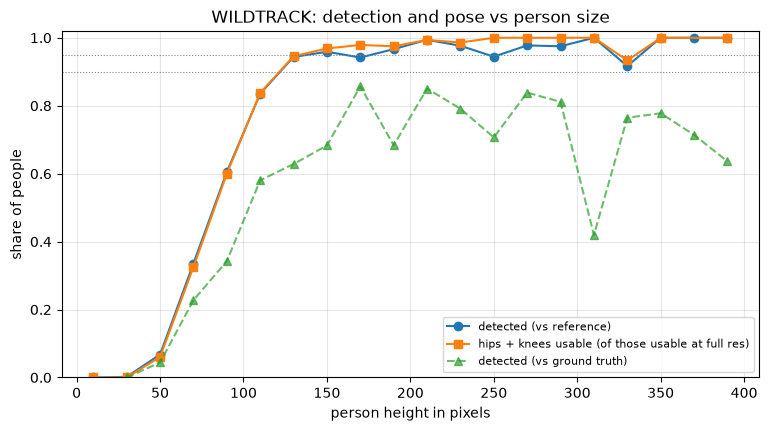

WILDTRACK: detection holds from ~350 px tall, hips/knees usable from ~130 px tall


In [8]:
plot_curves(cmpA_wt, "WILDTRACK: detection and pose vs person size", gt=cmpA_wt_gt)

x, y = curve(cmpA_wt, "detected")
h_det = height_threshold(x, y, CRITERIA["detect_recall_min"])
x, y = curve(cmpA_wt, "pose_ok", cmpA_wt.ref_pose_ok == True)
h_pose = height_threshold(x, y, CRITERIA["pose_keep_min"])
print(
    f"WILDTRACK: detection holds from ~{h_det:.0f} px tall, hips/knees usable from ~{h_pose:.0f} px tall"
)

### A7. Your site (after the GoPro test)

Repeats A on your own camera view. **This is the run that decides**, because your people are smaller from three stories up.

It then reads the curves at the size of the **smallest people in view** (5th percentile of heights) to get the minimum resolution.

Later refinement: restrict to people inside your study area, once the GoPro view is calibrated.

In [ ]:
if GOPRO_CLIP is None:
    print("Skipping A7: set GOPRO_CLIP in the settings cell.")
    summaryA_site = None
else:
    detA_site = run_scale_sweep(frames_from_video(GOPRO_CLIP, N_SAMPLE_FRAMES), "site")
    cmpA_site = compare_to_reference(detA_site)
    cap = cv2.VideoCapture(str(GOPRO_CLIP))
    native_site = (int(cap.get(4)), int(cap.get(3)))
    cap.release()
    summaryA_site = summarize_A(cmpA_site, max(native_site))
    display(summaryA_site)
    plot_curves(cmpA_site, "SITE: detection and pose vs person size")

    x, y = curve(cmpA_site, "detected")
    h_det_s = height_threshold(x, y, CRITERIA["detect_recall_min"])
    x, y = curve(cmpA_site, "pose_ok", cmpA_site.ref_pose_ok == True)
    h_pose_s = height_threshold(x, y, CRITERIA["pose_keep_min"])
    smallest = detA_site[detA_site.scale == 1.0].h_px.quantile(0.05)
    print(
        f"Smallest people in view: ~{smallest:.0f} px tall at native resolution ({native_site[1]}x{native_site[0]})"
    )
    for what, h in [("detection", h_det_s), ("pose", h_pose_s)]:
        need = h / smallest
        print(
            f"  {what}: needs ~{h:.0f} px -> minimum scale {need:.2f} "
            f"(~{native_site[1] * need:.0f} px wide)"
            if need <= 1
            else f"  {what}: needs ~{h:.0f} px -> NOT reached even at native resolution"
        )

---
## B. Frame rate + tracker: do tracks and speeds hold up?

**Needs:** the 30 fps GoPro clip (`GOPRO_CLIP`). Speed metrics also need the test view calibrated (`GOPRO_H`: pixels → meters, via your manual homography route). Tracking metrics work without it, in pixels.

For each frame rate × tracker: keep every nth frame, track, and compare with the reference (`REFERENCE_TRACKER` at the clip's full frame rate).

**The three trackers:**
- `bytetrack` matches by box overlap between frames (fails when people move far between frames)
- `botsort_reid` matches by appearance (ReID)
- `ground_distance` matches by nearest position on the ground plan, built here

**Fairness:** each tracker remembers lost people for `BUFFER_S` **seconds**, not a fixed number of frames, so low frame rates aren't penalized for that reason alone.

**Processing note:** every frame rate × tracker run re-processes the clip. Keep `CLIP_SECONDS` modest (60–120 s) for this test.

In [ ]:
from scipy.optimize import linear_sum_assignment
import yaml

H_SITE = np.load(GOPRO_H) if GOPRO_H else None


def video_frames(path, step, max_frames):
    cap = cv2.VideoCapture(str(path))
    i = 0
    while i < max_frames:
        if not cap.grab():
            break
        if i % step == 0:
            ok, img = cap.retrieve()
            if ok:
                yield i, img
        i += 1
    cap.release()


def tracker_yaml(kind, fps):
    # copy Ultralytics' tracker config; buffer set in seconds; ReID switched on for botsort_reid
    from ultralytics.utils import ROOT

    base = "bytetrack.yaml" if kind == "bytetrack" else "botsort.yaml"
    t = yaml.safe_load(open(ROOT / "cfg" / "trackers" / base))
    t["track_buffer"] = max(1, round(BUFFER_S * fps))
    if kind == "botsort_reid":
        t["with_reid"] = True
        t.setdefault("model", "auto")
    path = OUT / f"tracker_{kind}_{fps}fps.yaml"
    yaml.safe_dump(t, open(path, "w"))
    return str(path)


def add_ground(df):
    df = df.copy()
    df["foot_x"], df["foot_y"] = (df.x1 + df.x2) / 2, df.y2
    if H_SITE is not None:
        pts = cv2.perspectiveTransform(
            df[["foot_x", "foot_y"]].values.reshape(-1, 1, 2).astype(np.float64), H_SITE
        )
        df["gx"], df["gy"] = pts[:, 0, 0], pts[:, 0, 1]
    return df


def detections_30fps(force=False):
    # plain detection on every frame (no tracking); reused by the ground_distance tracker
    cache = OUT / "B_detections_fullrate.csv"
    if cache.exists() and not force:
        return pd.read_csv(cache)
    model, rows = YOLO(MODEL), []
    for i, img in video_frames(GOPRO_CLIP, 1, int(CLIP_SECONDS * GOPRO_CLIP_FPS)):
        boxes, conf, _ = detect(model, img, IMGSZ_B or imgsz_for(img.shape))
        rows += [
            dict(frame_idx=i, x1=b[0], y1=b[1], x2=b[2], y2=b[3], conf=c)
            for b, c in zip(boxes, conf)
        ]
    df = pd.DataFrame(rows)
    df.to_csv(cache, index=False)
    return df


def ground_distance_track(det):
    det = add_ground(det).sort_values("frame_idx").reset_index(drop=True)
    use_ground = "gx" in det
    cols = ["gx", "gy"] if use_ground else ["foot_x", "foot_y"]
    speed, slack = (MAX_SPEED_MS, 0.5) if use_ground else (PIXEL_SPEED_PX_S, 20)
    active, next_id, ids_out = {}, 0, np.empty(len(det), int)
    for f, g in det.groupby("frame_idx", sort=True):
        t = f / GOPRO_CLIP_FPS
        active = {
            k: v for k, v in active.items() if t - v[1] <= BUFFER_S
        }  # forget long-lost people
        P, assigned = g[cols].values, {}
        if active:
            keys = list(active)
            A = np.array([active[k][0] for k in keys])
            gap = np.array([t - active[k][1] for k in keys])
            D = np.linalg.norm(A[:, None, :] - P[None, :, :], axis=2)
            D = np.where(
                D <= (speed * gap + slack)[:, None], D, 1e6
            )  # too far = can't be them
            for r, c in zip(*linear_sum_assignment(D)):
                if D[r, c] < 1e6:
                    assigned[c] = keys[r]
        for local, idx in enumerate(g.index):
            tid = assigned.get(local)
            if tid is None:
                tid, next_id = next_id, next_id + 1
            ids_out[idx], active[tid] = tid, (P[local], t)
    det["track_id"] = ids_out
    return det


def run_tracking(kind, fps, force=False):
    cache = OUT / f"B_{kind}_{fps}fps.csv"
    if cache.exists() and not force:
        return pd.read_csv(cache)
    step = max(1, round(GOPRO_CLIP_FPS / fps))
    if kind == "ground_distance":
        det = detections_30fps()
        df = ground_distance_track(det[det.frame_idx % step == 0])
    else:
        model, ypath, rows = (
            YOLO(MODEL),
            tracker_yaml(kind, fps),
            [],
        )  # fresh model = fresh tracker
        for i, img in video_frames(
            GOPRO_CLIP, step, int(CLIP_SECONDS * GOPRO_CLIP_FPS)
        ):
            r = model.track(
                img,
                persist=True,
                tracker=ypath,
                imgsz=IMGSZ_B or imgsz_for(img.shape),
                conf=CONF,
                device=DEV,
                verbose=False,
            )[0]
            if r.boxes.id is None:
                continue
            for b, tid in zip(
                r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().cpu().numpy()
            ):
                rows.append(
                    dict(
                        frame_idx=i,
                        track_id=int(tid),
                        x1=b[0],
                        y1=b[1],
                        x2=b[2],
                        y2=b[3],
                    )
                )
        df = add_ground(pd.DataFrame(rows))
    df["t"] = df.frame_idx / GOPRO_CLIP_FPS
    df.to_csv(cache, index=False)
    return df


def add_speed(df):
    # speed = distance covered over at least SPEED_WINDOW_S, per track (needs ground coordinates)
    if "gx" not in df:
        return df.assign(speed=np.nan)
    parts = []
    for _, g in df.sort_values("t").groupby("track_id"):
        t, P = g.t.values, g[["gx", "gy"]].values
        j = np.searchsorted(t, t - SPEED_WINDOW_S, side="right") - 1
        sp, ok = np.full(len(t), np.nan), j >= 0
        sp[ok] = np.linalg.norm(P[ok] - P[j[ok]], axis=1) / (t[ok] - t[j[ok]])
        parts.append(g.assign(speed=sp))
    return pd.concat(parts)


def track_metrics(run, ref, min_ref_obs=5):
    ref_by_f = dict(tuple(ref.groupby("frame_idx")))
    pairs = []
    for f, g in run.groupby("frame_idx"):
        r = ref_by_f.get(f)
        if r is None:
            continue
        m = match(
            r[["x1", "y1", "x2", "y2"]].values, g[["x1", "y1", "x2", "y2"]].values
        )
        pairs += [
            (r.track_id.values[i], g.track_id.values[j], f)
            for i, j in enumerate(m)
            if j >= 0
        ]
    P = pd.DataFrame(pairs, columns=["ref_id", "run_id", "frame_idx"])
    seen = P.groupby("ref_id").size()
    pieces = (
        P[P.ref_id.isin(seen[seen >= min_ref_obs].index)]
        .groupby("ref_id")
        .run_id.nunique()
    )
    dur = run.groupby("track_id").t.agg(lambda x: x.max() - x.min())
    res = dict(
        tracks=run.track_id.nunique(),
        median_track_s=dur.median(),
        pieces_per_ref_track=pieces.mean(),
        speed_err=np.nan,
        stationary_share=np.nan,
    )
    if run.speed.notna().any():
        a = P.merge(
            run[["track_id", "frame_idx", "speed"]],
            left_on=["run_id", "frame_idx"],
            right_on=["track_id", "frame_idx"],
        )
        a = a.merge(
            ref[["track_id", "frame_idx", "speed"]],
            left_on=["ref_id", "frame_idx"],
            right_on=["track_id", "frame_idx"],
            suffixes=("_run", "_ref"),
        )
        res["speed_err"] = (a.speed_run - a.speed_ref).abs().median()
        res["stationary_share"] = (run.speed.dropna() < STATIONARY_MS).mean()
    return res

In [ ]:
if GOPRO_CLIP is None:
    print("Skipping B: set GOPRO_CLIP in the settings cell.")
    summaryB = None
else:
    ref = add_speed(run_tracking(REFERENCE_TRACKER, GOPRO_CLIP_FPS))
    print(
        f"Reference: {ref.track_id.nunique()} tracks, "
        f"stationary share {(ref.speed.dropna() < STATIONARY_MS).mean():.0%}"
        if ref.speed.notna().any()
        else ""
    )
    rows = []
    for kind in TRACKERS:
        for fps in FPS_LIST:
            run = add_speed(run_tracking(kind, fps))
            rows.append(dict(tracker=kind, fps=fps, **track_metrics(run, ref)))
            print(f"  {kind} @ {fps} fps done", end="\r")
    summaryB = pd.DataFrame(rows)
    speed_ok = summaryB.speed_err.isna() | (
        summaryB.speed_err <= CRITERIA["speed_err_max"]
    )
    summaryB["passes"] = (
        summaryB.pieces_per_ref_track <= CRITERIA["track_pieces_max"]
    ) & speed_ok
    summaryB.to_csv(OUT / "B_summary.csv", index=False)
    display(summaryB)

In [ ]:
if summaryB is not None:
    metrics = [
        (
            "pieces_per_ref_track",
            "pieces per reference track",
            CRITERIA["track_pieces_max"],
        ),
        ("median_track_s", "median track length (s)", None),
        ("speed_err", "median speed error (m/s)", CRITERIA["speed_err_max"]),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (col, label, limit) in zip(axes, metrics):
        for kind, g in summaryB.groupby("tracker"):
            ax.plot(g.fps, g[col], "o-", label=kind)
        if limit is not None:
            ax.axhline(limit, ls=":", c="grey")
        ax.set_xscale("log")
        ax.set_xticks(FPS_LIST)
        ax.set_xticklabels(FPS_LIST)
        ax.set_xlabel("frames per second")
        ax.set_title(label)
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.savefig(OUT / "B_metrics.png", dpi=150, bbox_inches="tight")
    plt.show()

---
## C. Processing cost

Times `TIMING_FRAMES` frames for each model × processing size on this computer, then turns that into hours to process 1, 2 and 4 days of footage.

Run it on the same computer you'll use for the real processing, since the numbers are hardware-specific.

In [ ]:
def time_model(model_name, imgsz, frames):
    model = YOLO(model_name)
    for img in frames[:5]:  # warm-up runs, not timed
        model(img, imgsz=imgsz, device=DEV, verbose=False)
    t0 = time.perf_counter()
    for img in frames:
        model(img, imgsz=imgsz, conf=CONF, device=DEV, verbose=False)
    return (time.perf_counter() - t0) / len(frames)


cacheC = OUT / "C_timing.csv"
if cacheC.exists():
    timing = pd.read_csv(cacheC)
    print(f"Using saved {cacheC.name}")
else:
    src = (
        frames_from_video(GOPRO_CLIP, TIMING_FRAMES)
        if GOPRO_CLIP
        else frames_from_folder(WILDTRACK_FRAMES, TIMING_FRAMES)
    )
    frames = [img for _, img in src]
    long_side = max(frames[0].shape[:2])
    rows = []
    for m in MODELS_TO_TIME:
        for s in SCALES:
            sz = imgsz_for((long_side, long_side), s)
            rows.append(
                dict(
                    model=m, scale=s, imgsz=sz, sec_per_frame=time_model(m, sz, frames)
                )
            )
            print(f"  {m} @ {sz}: {rows[-1]['sec_per_frame']:.3f} s/frame")
    timing = pd.DataFrame(rows)
    timing.to_csv(cacheC, index=False)
timing

In [ ]:
# hours of processing = frames per day x days x seconds per frame
frames_per_day = {fps: DAYLIGHT_HOURS * 3600 * fps for fps in FPS_LIST}
budget = []
for _, r in timing.iterrows():
    for fps in FPS_LIST:
        budget.append(
            dict(
                model=r.model,
                imgsz=r.imgsz,
                fps=fps,
                **{
                    f"{d}_day_hours": frames_per_day[fps] * d * r.sec_per_frame / 3600
                    for d in DAYS
                },
            )
        )
budget = pd.DataFrame(budget)
budget.to_csv(OUT / "C_budget.csv", index=False)
budget.pivot_table(index=["model", "imgsz"], columns="fps", values="2_day_hours").round(
    1
)

---
## D. Decision

Every combination of a passing resolution (A) and a passing frame rate + tracker (B), with its processing time from C. **The cheapest passing row is the choice.**

The decision should rest on **A7 (your site)**. If that hasn't run yet, WILDTRACK's results stand in, with a warning.

Once you're satisfied, write the chosen setting and the reasons into `Data/README.md` yourself.

In [ ]:
summaryA_use = summaryA_site if summaryA_site is not None else summaryA_wt
if summaryA_site is None:
    print("Note: using WILDTRACK for resolution; rerun after A7 for the real decision.")

if summaryB is None:
    print("Decision needs Part B (GoPro clip). Passing resolutions so far:")
    display(summaryA_use[summaryA_use.passes])
else:
    t = timing[timing.model == MODEL]
    cands = []
    for scale, a in summaryA_use[summaryA_use.passes].iterrows():
        spf = t.iloc[(t.imgsz - a.imgsz).abs().argsort()[:1]].sec_per_frame.values[
            0
        ]  # nearest timed size
        for _, b in summaryB[summaryB.passes].iterrows():
            cands.append(
                dict(
                    scale=scale,
                    imgsz=a.imgsz,
                    fps=b.fps,
                    tracker=b.tracker,
                    recall=a.recall,
                    pose_keep=a.pose_keep,
                    pieces=b.pieces_per_ref_track,
                    speed_err=b.speed_err,
                    hours_2_days=frames_per_day[b.fps] * 2 * spf / 3600,
                )
            )
    decision = pd.DataFrame(cands).sort_values("hours_2_days")
    decision.to_csv(OUT / "D_candidates.csv", index=False)
    display(decision.head(10))
    if len(decision):
        best = decision.iloc[0].to_dict()
        json.dump(
            {"chosen": best, "criteria": CRITERIA, "model": MODEL},
            open(OUT / "D_decision.json", "w"),
            indent=2,
            default=float,
        )
        print("Cheapest passing setting:", best)
    else:
        print(
            "Nothing passes every criterion: revisit the camera position or the criteria."
        )